
# Time Series with Pandas

## 1️ Create a Simple Time Series Dataset


In [1]:
import pandas as pd
import numpy as np

# Create date range
dates = pd.date_range(start='2024-01-01', periods=100, freq='D')

# Create dummy data (sales with trend + noise)
np.random.seed(42)
sales = np.random.randint(100, 200, size=100) + np.arange(100)

# Create DataFrame
df = pd.DataFrame({'date': dates, 'sales': sales})

df.head()

,date,sales
0,2024-01-01,151
1,2024-01-02,193
2,2024-01-03,116
3,2024-01-04,174
4,2024-01-05,164


* `pd.date_range()` → creates time index
* `freq='D'` → daily data

In [ ]:


## 2️ Set Date as Index (VERY IMPORTANT)


In [3]:
df.set_index('date', inplace=True)

df.head()

,sales
date,
2024-01-01,151
2024-01-02,193
2024-01-03,116
2024-01-04,174
2024-01-05,164


Key concept:

> Pandas time series works best when **date is the index**

## 3️ Basic Plot (Visual Understanding)

<Axes: title={'center': 'Daily Sales'}, xlabel='date'>

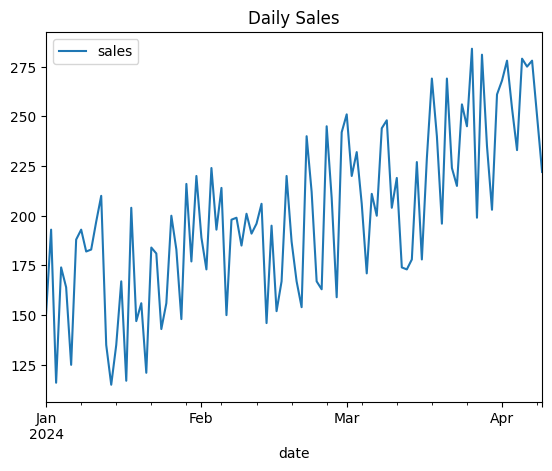

In [4]:
df.plot(title="Daily Sales")

Question:

* Is trend increasing?
* Any randomness?


## 4️ Accessing Data Using Dates

In [5]:
# Single date
df.loc['2024-01-10']


sales    183
Name: 2024-01-10 00:00:00, dtype: int64

In [6]:

# Date range
df.loc['2024-01-10':'2024-01-20']


,sales
date,
2024-01-10,183
2024-01-11,197
2024-01-12,210
2024-01-13,135
2024-01-14,115
2024-01-15,135
2024-01-16,167
2024-01-17,117
2024-01-18,204


In [ ]:
## 5 Extract Date Features

In [ ]:
df['year'] = df.index.year
df['month'] = df.index.month
df['day'] = df.index.day
df['day_of_week'] = df.index.day_name()

df.head()


```
Very useful for ML models later


## 6️ Resampling (Change Frequency)

In [10]:
# Monthly sales (sum)
monthly = df.resample('ME').sum()

monthly

,sales
date,
2024-01-31,5181
2024-02-29,5544
2024-03-31,6942
2024-04-30,2337


<Axes: title={'center': 'Monthly Sales'}, xlabel='date'>

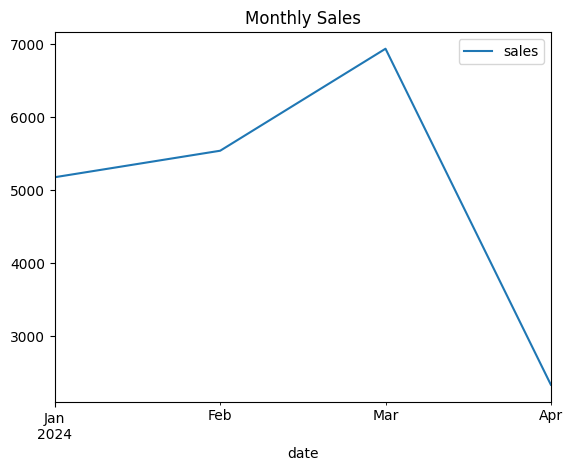

In [11]:
monthly.plot(title="Monthly Sales")



* `'D'` → daily
* `'M'` → monthly
* `'Y'` → yearly


In [ ]:
## 7️ Rolling Statistics (Moving Average)

<Axes: title={'center': '7-Day Rolling Mean'}, xlabel='date'>

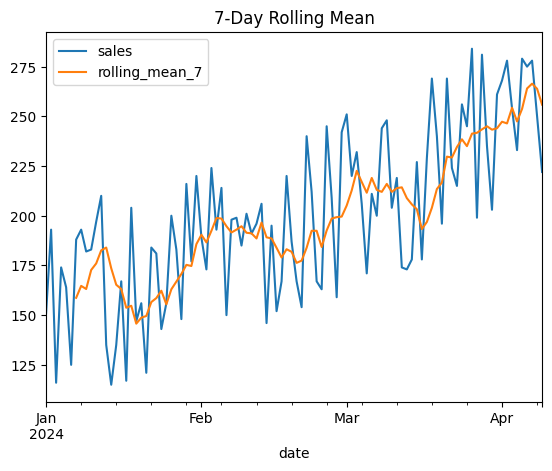

In [12]:
# 7-day moving average
df['rolling_mean_7'] = df['sales'].rolling(window=7).mean()

df[['sales', 'rolling_mean_7']].plot(title="7-Day Rolling Mean")


## Observation:

* Smooths fluctuations
* Helps see trend


## 8️ Shifting Data (Lag Features)


In [13]:
df['lag_1'] = df['sales'].shift(1)
df['lag_7'] = df['sales'].shift(7)

df.head(10)


,sales,rolling_mean_7,lag_1,lag_7
date,,,,
2024-01-01,151,NaN,NaN,NaN
2024-01-02,193,NaN,151.0,NaN
2024-01-03,116,NaN,193.0,NaN
2024-01-04,174,NaN,116.0,NaN
2024-01-05,164,NaN,174.0,NaN
2024-01-06,125,NaN,164.0,NaN
2024-01-07,188,158.714286,125.0,NaN
2024-01-08,193,164.714286,188.0,151.0
2024-01-09,182,163.142857,193.0,193.0


In [ ]:
### Observation:

* Yesterday’s value → predict today
* Important for forecasting


## 9️ Handling Missing Values

In [14]:
# Create missing values
df_missing = df.copy()
df_missing.iloc[5:10] = np.nan

# Fill missing values
df_missing['sales_filled'] = df_missing['sales'].fillna(method='ffill')

df_missing.head(15)


C:\Users\hi\AppData\Local\Temp\ipykernel_9328\2847075865.py:6: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_missing['sales_filled'] = df_missing['sales'].fillna(method='ffill')


,sales,rolling_mean_7,lag_1,lag_7,sales_filled
date,,,,,
2024-01-01,151.0,NaN,NaN,NaN,151.0
2024-01-02,193.0,NaN,151.0,NaN,193.0
2024-01-03,116.0,NaN,193.0,NaN,116.0
2024-01-04,174.0,NaN,116.0,NaN,174.0
2024-01-05,164.0,NaN,174.0,NaN,164.0
2024-01-06,NaN,NaN,NaN,NaN,164.0
2024-01-07,NaN,NaN,NaN,NaN,164.0
2024-01-08,NaN,NaN,NaN,NaN,164.0
2024-01-09,NaN,NaN,NaN,NaN,164.0


### Observation:

* `ffill` → forward fill
* `bfill` → backward fill


In [ ]:
## 🔟 Time-Based Filtering

In [19]:
# Filter one month
jan_data = df.loc['2024-01']
jan_data


,sales,rolling_mean_7,lag_1,lag_7,cumulative_mean,diff
date,,,,,,
2024-01-01,151,NaN,NaN,NaN,151.000000,NaN
2024-01-02,193,NaN,151.0,NaN,172.000000,42.0
2024-01-03,116,NaN,193.0,NaN,153.333333,-77.0
2024-01-04,174,NaN,116.0,NaN,158.500000,58.0
2024-01-05,164,NaN,174.0,NaN,159.600000,-10.0
2024-01-06,125,NaN,164.0,NaN,153.833333,-39.0
2024-01-07,188,158.714286,125.0,NaN,158.714286,63.0
2024-01-08,193,164.714286,188.0,151.0,163.000000,5.0
2024-01-09,182,163.142857,193.0,193.0,165.111111,-11.0


In [ ]:
## 11 Expanding Window (Cumulative Stats)

<Axes: title={'center': 'Cumulative Mean'}, xlabel='date'>

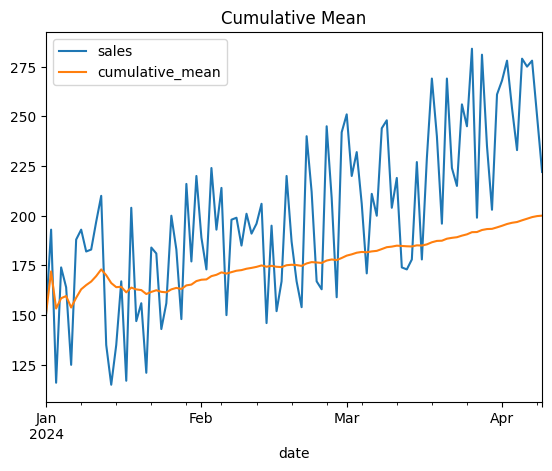

In [16]:
df['cumulative_mean'] = df['sales'].expanding().mean()

df[['sales', 'cumulative_mean']].plot(title="Cumulative Mean")



Uses all past data

In [ ]:
## 12 Difference (Trend Removal)

<Axes: title={'center': 'Differencing'}, xlabel='date'>

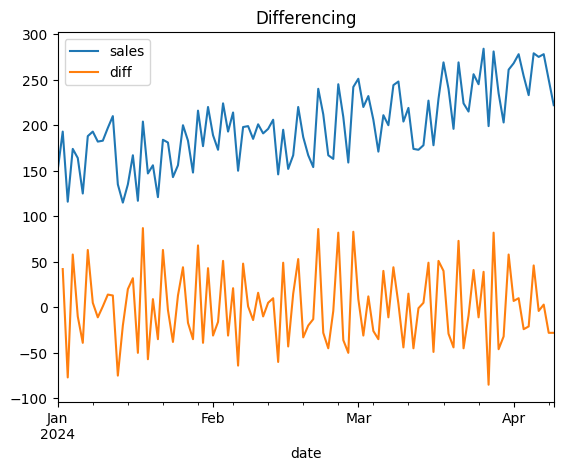

In [17]:
df['diff'] = df['sales'].diff()

df[['sales', 'diff']].plot(title="Differencing")

### Observation:

* Removes trend
* Used in forecasting


In [ ]:

---

## Summary of Important Pandas Methods

| Concept           | Method            |
| ----------------- | ----------------- |
| Create time index | `pd.date_range()` |
| Set index         | `.set_index()`    |
| Select by date    | `.loc[]`          |
| Resample          | `.resample()`     |
| Rolling stats     | `.rolling()`      |
| Lag features      | `.shift()`        |
| Missing values    | `.fillna()`       |
| Expanding stats   | `.expanding()`    |
| Trend removal     | `.diff()`         |

---
